# IoE Framework & 5G/6G Communication Benchmarking
This notebook contains the implementation of:
1. **People-Process-Data-Things (P-P-D-T)** simulation engine.
2. **Edge/Fog-to-Cloud pipeline** processing comparisons.
3. Comparative benchmarking visualizations of **5G vs 6G** network parameters (Throughput, Latency, Reliability, and Energy Efficiency).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import random

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

# Configure visual aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 14

## 1. P-P-D-T Data Flow Simulation
We model the structured interaction of the four core pillars of the Internet of Everything (IoE):
*   **People**: Wearable vital data (Heart rate, Activity indexes).
*   **Things**: Environmental IoT Telemetry (Temperature, Humidity, Vibration).
*   **Data**: Payload size, timestamps, structured stream data packets.
*   **Process**: Triggering logic based on anomalies (e.g., local warning flags).

In [2]:
def generate_ppdt_stream(num_samples=1000):
    timestamps = pd.date_range(start="2026-01-01", periods=num_samples, freq="s")

    # Things (Sensors)
    temp = np.random.normal(loc=24.0, scale=1.5, size=num_samples)
    vibration = np.random.normal(loc=0.05, scale=0.01, size=num_samples)

    # People (Wearables)
    heart_rate = np.random.normal(loc=72, scale=8, size=num_samples).astype(int)
    activity_index = np.random.choice([0, 1, 2], size=num_samples, p=[0.6, 0.3, 0.1]) # Rest, Walk, Run

    # Assemble Base Data
    df = pd.DataFrame({
        "timestamp": timestamps,
        "thing_temp_celsius": temp,
        "thing_vibration_g": vibration,
        "people_heart_rate": heart_rate,
        "people_activity": activity_index,
        "data_packet_size_kb": np.random.choice([2, 4, 8, 16], size=num_samples, p=[0.5, 0.3, 0.15, 0.05])
    })

    # Process Engine (Defining trigger logic for anomalies)
    # e.g., High heart rate combined with running or abnormal system vibration
    df["process_alert_triggered"] = (
        ((df["people_heart_rate"] > 95) & (df["people_activity"] == 0)) |
        (df["thing_vibration_g"] > 0.075)
    ).astype(int)

    return df

ppdt_df = generate_ppdt_stream(num_samples=500)
display(ppdt_df.head(10))

,timestamp,thing_temp_celsius,thing_vibration_g,people_heart_rate,people_activity,data_packet_size_kb,process_alert_triggered
0,2026-01-01 00:00:00,24.745071,0.059262,83,0,2,0
1,2026-01-01 00:00:01,23.792604,0.069094,79,1,2,0
2,2026-01-01 00:00:02,24.971533,0.036014,72,0,4,0
3,2026-01-01 00:00:03,26.284545,0.055630,66,0,2,0
4,2026-01-01 00:00:04,23.648770,0.043494,77,0,4,0
5,2026-01-01 00:00:05,23.648795,0.045129,75,0,4,0
6,2026-01-01 00:00:06,26.368819,0.044076,79,1,4,0
7,2026-01-01 00:00:07,25.151152,0.041360,77,1,8,0
8,2026-01-01 00:00:08,23.295788,0.050485,80,1,2,0
9,2026-01-01 00:00:09,24.813840,0.041690,67,0,2,0


## 2. Edge/Fog-to-Cloud Pipeline Performance Evaluation
Comparing processing latency when processing events locally at Edge/Fog node vs. routing raw data all the way back to the Centralized Cloud.

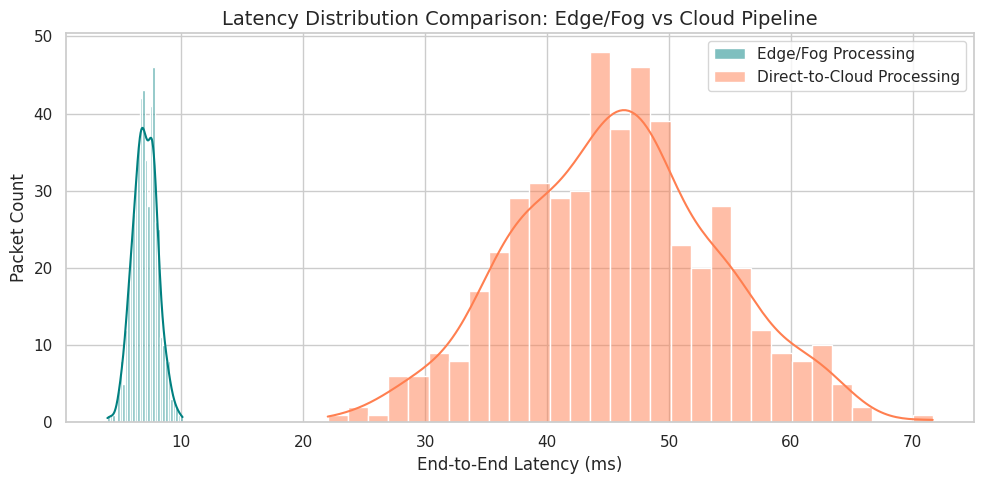

In [3]:
def evaluate_pipeline_performance(df):
    # Simulated propagation & processing parameters (in milliseconds)
    # Edge: Low transport delay, moderate local compute constraint
    edge_network_delay = np.random.normal(loc=5, scale=1, size=len(df)) # 5ms average
    edge_compute_delay = np.random.normal(loc=2, scale=0.3, size=len(df)) # 2ms local decision

    # Cloud: High transport delay, fast/scalable compute
    cloud_network_delay = np.random.normal(loc=45, scale=8, size=len(df)) # 45ms average WAN
    cloud_compute_delay = np.random.normal(loc=0.5, scale=0.1, size=len(df)) # 0.5ms ultra-fast cloud nodes

    df_perf = df.copy()
    df_perf["edge_total_latency_ms"] = edge_network_delay + edge_compute_delay
    df_perf["cloud_total_latency_ms"] = cloud_network_delay + cloud_compute_delay

    return df_perf

ppdt_perf_df = evaluate_pipeline_performance(ppdt_df)

# Visualize latency profile distributions
plt.figure(figsize=(10, 5))
sns.histplot(ppdt_perf_df["edge_total_latency_ms"], color="teal", label="Edge/Fog Processing", kde=True, bins=30)
sns.histplot(ppdt_perf_df["cloud_total_latency_ms"], color="coral", label="Direct-to-Cloud Processing", kde=True, bins=30)
plt.title("Latency Distribution Comparison: Edge/Fog vs Cloud Pipeline")
plt.xlabel("End-to-End Latency (ms)")
plt.ylabel("Packet Count")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Benchmarking 5G vs 6G Communication for IoE Applications
We model and visualize simulated telemetry comparing 5G and 6G standards across key performance indicators (KPIs).

In [4]:
# Define typical synthetic performance stats for 5G and 6G technologies
metrics = ["Throughput (Gbps)", "Latency (ms)", "Reliability (% packets received)", "Energy Efficiency (J/Mb)"]

# Average target figures from literature specifications
# 5G: ~20 Gbps peak, ~1-5ms air interface latency, 99.999% reliability, standard energy budget
# 6G: ~1000 Gbps peak, ~0.1ms air interface latency, 99.99999% reliability, 10x energy efficiency optimization

performance_data = {
    "Metric": ["Throughput (Gbps)", "Throughput (Gbps)",
               "Latency (ms)", "Latency (ms)",
               "Reliability (%)", "Reliability (%)",
               "Energy Consumption (nJ/bit)", "Energy Consumption (nJ/bit)"],
    "Standard": ["5G", "6G", "5G", "6G", "5G", "6G", "5G", "6G"],
    "Value": [20.0, 1000.0, 1.0, 0.1, 99.999, 99.99999, 1.2, 0.08]
}

benchmark_df = pd.DataFrame(performance_data)
display(benchmark_df)

,Metric,Standard,Value
0,Throughput (Gbps),5G,20.00000
1,Throughput (Gbps),6G,1000.00000
2,Latency (ms),5G,1.00000
3,Latency (ms),6G,0.10000
4,Reliability (%),5G,99.99900
5,Reliability (%),6G,99.99999
6,Energy Consumption (nJ/bit),5G,1.20000
7,Energy Consumption (nJ/bit),6G,0.08000


/tmp/ipykernel_1737/1307282718.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0, 0], x="Standard", y="Value", data=benchmark_df[benchmark_df["Metric"] == "Throughput (Gbps)"], palette="Blues_d")
/tmp/ipykernel_1737/1307282718.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0, 1], x="Standard", y="Value", data=benchmark_df[benchmark_df["Metric"] == "Latency (ms)"], palette="Oranges_r")
/tmp/ipykernel_1737/1307282718.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1, 0], x="Standard", y="Value", data=benc

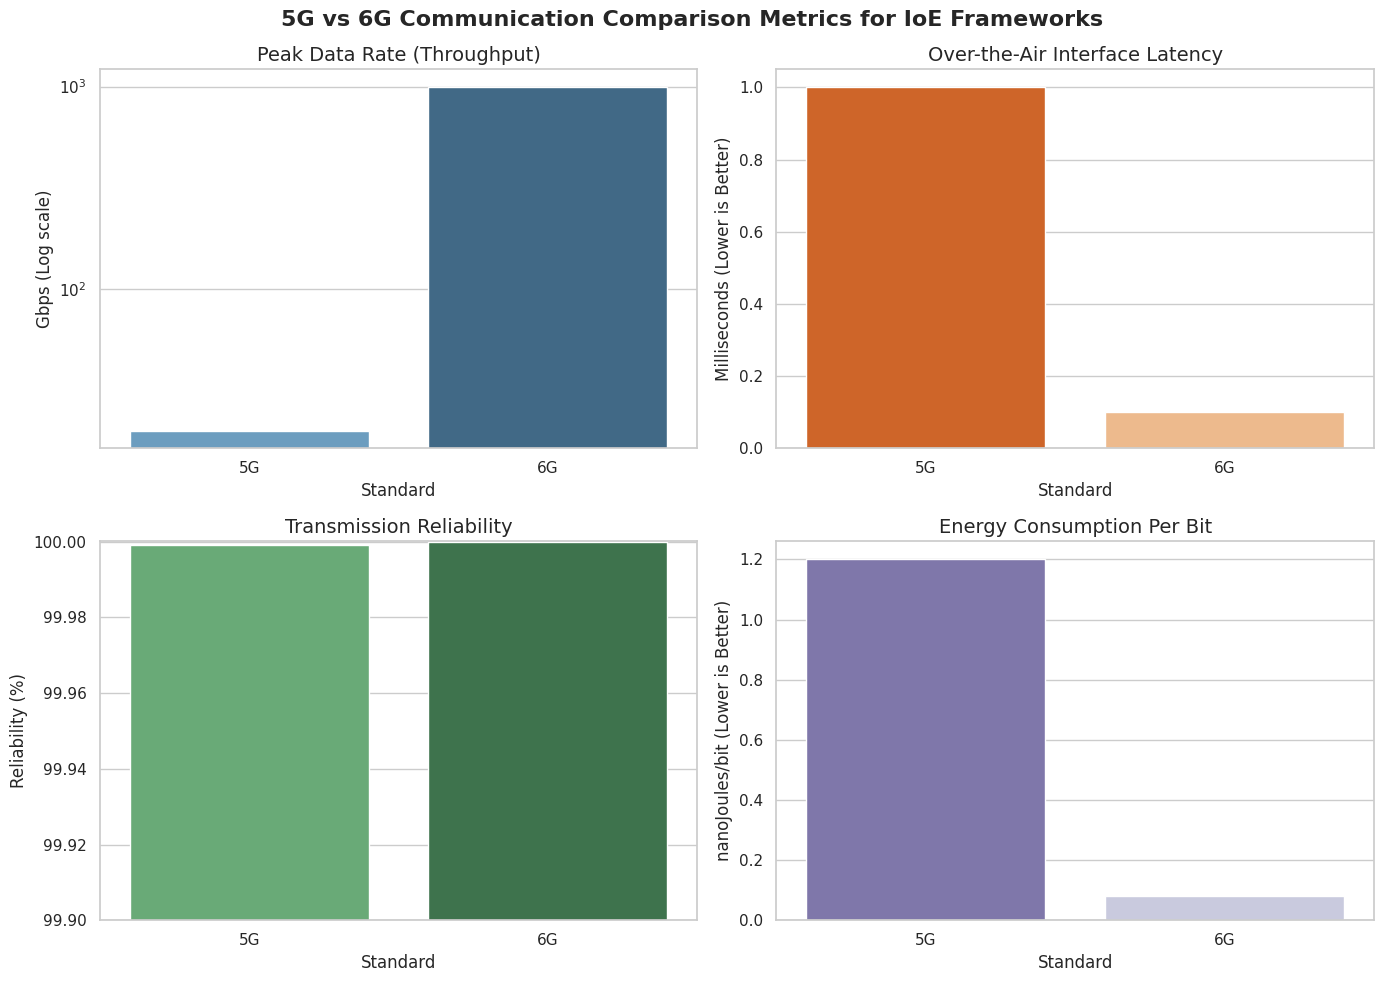

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Throughput Comparison
sns.barplot(ax=axes[0, 0], x="Standard", y="Value", data=benchmark_df[benchmark_df["Metric"] == "Throughput (Gbps)"], palette="Blues_d")
axes[0, 0].set_title("Peak Data Rate (Throughput)")
axes[0, 0].set_ylabel("Gbps (Log scale)")
axes[0, 0].set_yscale("log")

# 2. Latency Comparison
sns.barplot(ax=axes[0, 1], x="Standard", y="Value", data=benchmark_df[benchmark_df["Metric"] == "Latency (ms)"], palette="Oranges_r")
axes[0, 1].set_title("Over-the-Air Interface Latency")
axes[0, 1].set_ylabel("Milliseconds (Lower is Better)")

# 3. Reliability Comparison
sns.barplot(ax=axes[1, 0], x="Standard", y="Value", data=benchmark_df[benchmark_df["Metric"] == "Reliability (%)"], palette="Greens_d")
axes[1, 0].set_title("Transmission Reliability")
axes[1, 0].set_ylabel("Reliability (%)")
axes[1, 0].set_ylim(99.9, 100.0001)

# 4. Energy Efficiency
sns.barplot(ax=axes[1, 1], x="Standard", y="Value", data=benchmark_df[benchmark_df["Metric"] == "Energy Consumption (nJ/bit)"], palette="Purples_r")
axes[1, 1].set_title("Energy Consumption Per Bit")
axes[1, 1].set_ylabel("nanoJoules/bit (Lower is Better)")

plt.suptitle("5G vs 6G Communication Comparison Metrics for IoE Frameworks", fontsize=16, weight='bold')
plt.tight_layout()
plt.show()